# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)
print("\nTypes de chaque colonne :\n", brut.dtypes)
print("\nValeurs manquantes par colonne :\n", brut.isna().sum())
print("\nNombre de lignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types de chaque colonne :
 mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes par colonne :
 mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Nombre de lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [6]:
nb_ecritures = brut["quartier"].nunique()
print(f"Nombre d'écritures différentes : {nb_ecritures}")

Nombre d'écritures différentes : 43


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [7]:

non_convertibles = brut[
    pd.to_numeric(brut["kwh"], errors="coerce").isna() & brut["kwh"].notna()
]["kwh"]
print("Valeurs non convertibles en nombre :")
print(non_convertibles.unique())

Valeurs non convertibles en nombre :
<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [8]:
propre = brut.copy()

# Retrait de "kWh" et des espaces, puis conversion en numérique
propre["kwh"] = (
    propre["kwh"]
    .astype(str)
    .str.replace("kWh", "", case=False)
    .str.replace(" ", "")
)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

print("Nombre de manquants restants :", propre["kwh"].isna().sum())

Nombre de manquants restants : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [9]:
quartiers = pd.read_csv("donnees/quartiers.csv")
dico_quartiers = {q.lower().strip(): q for q in quartiers["quartier"]}

propre["quartier"] = (
    propre["quartier"].astype(str).str.strip().str.lower().map(dico_quartiers)
)

print("Nombre de quartiers uniques :", propre["quartier"].nunique())
print("Nombre de valeurs manquantes après map :", propre["quartier"].isna().sum())

Nombre de quartiers uniques : 12
Nombre de valeurs manquantes après map : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [10]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
print("Forme de propre :", propre.shape)

Forme de propre : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [11]:
medianes = propre.groupby("quartier")["kwh"].transform("median")
anomalies = propre["kwh"] > 3 * medianes

print("Relevés anormaux détectés :")
print(propre.loc[anomalies, ["mois", "quartier", "kwh"]])

propre.loc[anomalies, "kwh"] = propre.loc[anomalies, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)

print("\nMaximum de kwh :", propre["kwh"].max())

Relevés anormaux détectés :
        mois        quartier        kwh
90   2025-02       Delmas 33  3602600.0
140  2025-02       Delmas 75  2012700.0
200  2024-02  Morne Calvaire  1439200.0
251  2024-01          Rue 15   997700.0

Maximum de kwh : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [12]:
ref = pd.read_csv("donnees/consommation.csv")
colonnes = propre.columns.tolist()

# Alignement de ref sur les mêmes lignes et mêmes colonnes que propre
ref_aligne = ref.merge(propre[["mois", "quartier"]], on=["mois", "quartier"])[colonnes]
propre = propre.reset_index(drop=True)

print(propre.equals(ref_aligne))

True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [13]:
print("Lignes avant la jointure :", len(propre))
avec_quartiers = propre.merge(quartiers, on="quartier")
print("Lignes après la jointure :", len(avec_quartiers))

avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

bpc_test = avec_quartiers[
    (avec_quartiers["quartier"] == "Bas-Peu-de-Chose")
    & (avec_quartiers["mois"] == "2024-01")
]
print("\nBas-Peu-de-Chose en 2024-01 :")
print(bpc_test[["quartier", "mois", "kwh_par_abonne", "annee"]])

Lignes avant la jointure : 279
Lignes après la jointure : 279

Bas-Peu-de-Chose en 2024-01 :
           quartier     mois  kwh_par_abonne  annee
0  Bas-Peu-de-Chose  2024-01            85.8   2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [14]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Lignes avant la jointure :", len(avec_quartiers))
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"])
print("Lignes après la jointure :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes avant la jointure : 279
Lignes après la jointure : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [15]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

consommation_propre = pd.read_csv("donnees/consommation_propre.csv")
print("Forme du fichier lu :", consommation_propre.shape)

Forme du fichier lu : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [16]:

moyenne_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Consommation moyenne par abonné par type de quartier :")
print(moyenne_type)

print("\nClassement des 12 quartiers :")
classement_quartiers = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"].mean().round(1)
).sort_values(ascending=False)
print(classement_quartiers)

Consommation moyenne par abonné par type de quartier :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Tableau de la consommation par commune et par année :
annee            2024   2025  hausse_%
commune                               
Cap-Haïtien      4.59   5.62      22.5
Pétion-Ville     8.60   9.68      12.6
Port-au-Prince  10.09  10.31       2.3
Delmas          11.61  11.74       1.1


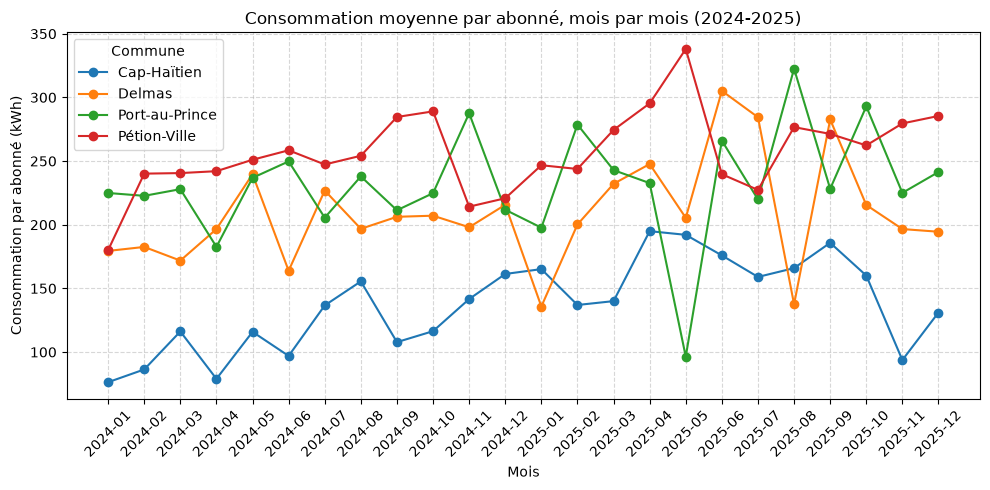

In [17]:

tableau = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
)


tableau["hausse_%"] = (
    ((tableau[2025] - tableau[2024]) / tableau[2024] * 100).round(1)
)


tableau[2024] = (tableau[2024] / 1e6).round(2)
tableau[2025] = (tableau[2025] / 1e6).round(2)

tableau = tableau.sort_values("hausse_%", ascending=False)
print("Tableau de la consommation par commune et par année :")
print(tableau)


plt.figure(figsize=(10, 5))
evol_commune = (
    avec_meteo.groupby(["mois", "commune"])["kwh_par_abonne"]
    .mean()
    .unstack()
)
for commune in evol_commune.columns:
    plt.plot(evol_commune.index, evol_commune[commune], marker="o", label=commune)

plt.title("Consommation moyenne par abonné, mois par mois (2024-2025)")
plt.xlabel("Mois")
plt.ylabel("Consommation par abonné (kWh)")
plt.xticks(rotation=45)
plt.legend(title="Commune")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

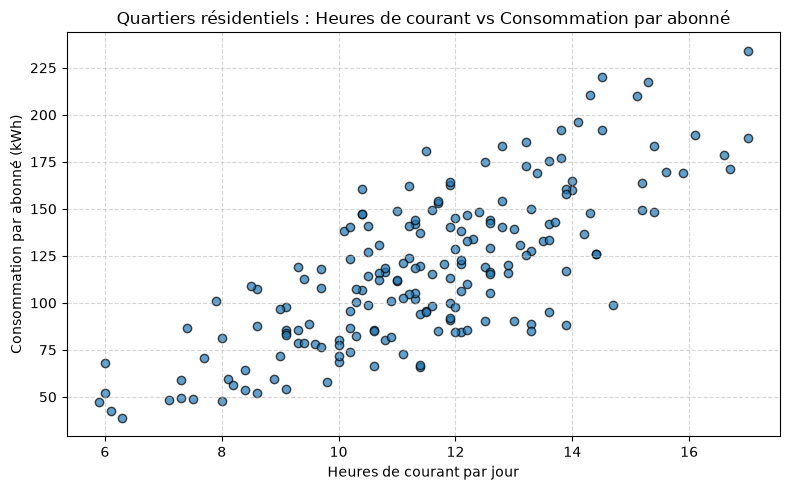

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [18]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

plt.figure(figsize=(8, 5))
plt.scatter(
    residentiel["heures_courant"],
    residentiel["kwh_par_abonne"],
    color="#1f77b4",
    alpha=0.7,
    edgecolor="k",
)
plt.title("Quartiers résidentiels : Heures de courant vs Consommation par abonné")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Consommation par abonné (kWh)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_temp = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])

print(f"Corrélation avec les heures de courant : {corr_courant:.2f}")
print(f"Corrélation avec la température : {corr_temp:.2f}")

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Statistiques des heures de courant par commune :
                mediane    Q1    Q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


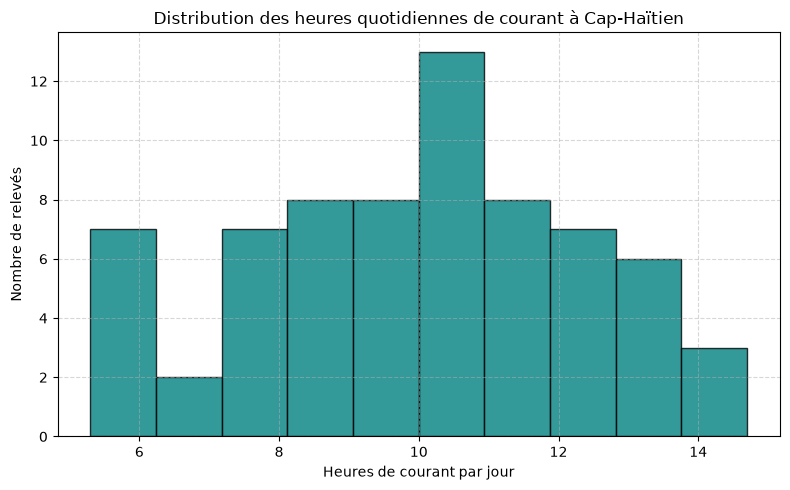


Nombre de relevés en 2025 avec moins de 8h de courant : 3
        mois   quartier      commune  heures_courant
81   2025-01  Delmas 33       Delmas             7.4
227  2025-08   Carénage  Cap-Haïtien             7.3
253  2025-11     Rue 15  Cap-Haïtien             5.9


In [19]:

stats_courant = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
).round(1)
print("Statistiques des heures de courant par commune :")
print(stats_courant)


plt.figure(figsize=(8, 5))
cap = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"]
plt.hist(cap["heures_courant"], bins=10, color="teal", edgecolor="black", alpha=0.8)
plt.title("Distribution des heures quotidiennes de courant à Cap-Haïtien")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


releves_2025_inf_8 = avec_meteo[
    (avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)
]
print(f"\nNombre de relevés en 2025 avec moins de 8h de courant : {len(releves_2025_inf_8)}")
print(releves_2025_inf_8[["mois", "quartier", "commune", "heures_courant"]])

**Ce qu'on en conclut : C'est à Cap-Haïtien que les coupures de courant sont les plus prolongées, avec une médiane de seulement 10.0 heures d'électricité par jour, contre 11.6 à 11.9 heures dans les autres communes. Durant l'année 2025, trois relevés sont passés sous le seuil critique des 8 heures quotidiennes de service : à Carénage (7.3 h) et Rue 15 (5.9 h) à Cap-Haïtien, ainsi qu'à Delmas 33 (7.4 h).

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [20]:
top3 = avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print("Les 3 plus grosses consommations :")
print(top3)

Les 3 plus grosses consommations :
       mois      quartier        type     kwh
87  2025-07     Delmas 33  Commercial  742780
56  2024-11  Centre-ville  Commercial  597730
88  2025-09     Delmas 33  Commercial  591420


**Ce qu'on en conclut :Les trois relevés les plus élevés de tout le fichier proviennent exclusivement de quartiers commerciaux : Delmas 33 en juillet 2025 (742 780 kWh), le Centre-ville en novembre 2024 (597 730 kWh) et de nouveau Delmas 33 en septembre 2025 (591 420 kWh). Ces valeurs de pointe reflètent la concentration de la demande électrique dans les grands centres d'activité commerciale.**

## 9. Conclusion

1. La consommation d'électricité suit nettement les heures de courant fournies (forte corrélation de **0.76** en résidentiel) plutôt que la chaleur (**-0.15** avec la température), révélant un système contraint par l'offre où les usagers consomment dès que le service est disponible.
2. Les communes font face à de fortes disparités, Cap-Haïtien enregistrant les coupures les plus sévères (médiane de **10.0 heures** de courant par jour contre 11.6 à 11.9 h ailleurs), tandis que les zones commerciales (Centre-ville à **468.7 kWh/abonné**, Place Saint-Pierre à **458.3 kWh/abonné**) représentent les plus hauts niveaux d'usage.
3. Toutefois, une forte corrélation ne démontre pas de lien de causalité direct et ne permet pas de quantifier la demande latente non satisfaite si l'électricité était distribuée en continu 24h sur 24.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.